# 08 – NHL EDGE data (2025-26)

Notebook 07 pulled skating and shot data live from the NHL for one player at a time. This notebook downloads it **once for every skater** and saves it, so:
- cards load instantly and work offline
- the NHL's server isn't hit every time a card is drawn
- EDGE stats get **our own percentiles**, calculated the same way as every other row on the card (vs. qualified players at the same position)

Each player's raw response is saved as its own file in `data/edge_raw/2025-26/`. If the download stops partway, run it again and it picks up where it left off. The raw files stay on this computer (they're in `.gitignore`).

NHL EDGE data exists from 2021-22 on, so the same code works for all five seasons later.

Source: NHL EDGE (api-web.nhle.com), regular season.

## 1. Setup

In [ ]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from war_model import run_season, V04_PARAMS
from edge_data import download_season, build_table, download_bios, build_bio_table
from player_card import build_metrics, add_percentiles, add_edge, add_bio, draw_card, percentile_in
import numpy as np

DATA = Path("../data")
SEASON_FILE = DATA / "skaters25-26.csv"
SEASON_LABEL = "2025-26"
SEASON_CODE = "20252026"
RAW_DIR = DATA / "edge_raw" / SEASON_LABEL
BIO_DIR = DATA / "bio_raw"          # player profiles (birth date, draft), not season-specific
SEASON_END_YEAR = 2026              # age is measured on Feb 1 of the season

war = run_season(SEASON_FILE, V04_PARAMS)
player_ids = war["playerId"].tolist()
print("Skaters to download:", len(player_ids))

Skaters to download: 940


## 2. Download
About 10 minutes for a full season. Progress prints every 50 players. If it stops or anything fails, just run this cell again.

In [ ]:
failed = download_season(player_ids, SEASON_CODE, RAW_DIR)

940 already saved, 0 to download (about 0 minutes)
Done, no failures.


## 3. Build the table

In [ ]:
edge = build_table(RAW_DIR)
edge.to_csv(DATA / f"edge_{SEASON_LABEL}.csv", index=False)

names = war[["playerId", "name", "team", "position", "games_played"]]
edge = edge.merge(names, on="playerId", how="left")

print("Saved", len(edge), "players to", f"data/edge_{SEASON_LABEL}.csv")
print("With EDGE data:", int(edge["has_edge"].sum()), "| without:", int((~edge["has_edge"]).sum()))
print("\nPlayers without EDGE data (fewest games first):")
print(edge[~edge["has_edge"]].sort_values("games_played")[["name", "team", "games_played"]].head(10).to_string(index=False))

Saved 940 players to data/edge_2025-26.csv
With EDGE data: 940 | without: 0

Players without EDGE data (fewest games first):
Empty DataFrame
Columns: [name, team, games_played]
Index: []


### Sanity check: fastest skaters and hardest shots
These should match the names you'd expect.

In [ ]:
print("Top skating speed (mph)")
print(edge.nlargest(10, "top_speed")[["name", "team", "position", "top_speed"]].round(2).to_string(index=False))
print("\nTop shot speed (mph)")
print(edge.nlargest(10, "shot_speed")[["name", "team", "position", "shot_speed"]].round(2).to_string(index=False))

Top skating speed (mph)
            name team position  top_speed
  Beck Malenstyn  BUF        L      24.94
Nathan MacKinnon  COL        C      24.78
  Connor McDavid  EDM        C      24.61
    Logan Cooley  UTA        C      24.38
  Jake Sanderson  OTT        D      24.37
    Ryan Leonard  WSH        R      24.26
    Bobby McMann  SEA        C      24.25
    Trevor Moore  LAK        L      24.22
     Cole Koepke  WPG        L      24.22
    Owen Tippett  PHI        R      23.97

Top shot speed (mph)
           name team position  shot_speed
   Tyler Kleven  OTT        D      103.51
  Morgan Geekie  BOS        C      103.03
    Ryan Pulock  NYI        D      103.01
  Louis Crevier  CHI        D      102.83
    J.T. Miller  NYR        C      102.58
   Colin Miller  WPG        D      102.47
    Jake Walman  EDM        D      101.97
Brandon Montour  SEA        D      101.56
  Victor Hedman  TBL        D      101.42
  Conor Timmins  BUF        D      101.12


## 4. Age and draft position
For the card header ("Age 20 · 2024 Draft, #2 overall"). This is a second download from the NHL's player profiles, also about 10 minutes the first time and skipped after that. Age is measured on February 1 of the season, hockey's usual "season age."

In [ ]:
failed_bios = download_bios(player_ids, BIO_DIR)
bios = build_bio_table(BIO_DIR, SEASON_END_YEAR)
bios = bios.merge(names, on="playerId", how="left")
print("Profiles:", int(bios["has_bio"].sum()), "of", len(bios), "| undrafted:", int((bios["has_bio"] & bios["draft_overall"].isna()).sum()))
print("\nYoungest qualified skaters:")
young = bios.merge(war[["playerId", "ev_toi"]], on="playerId")
print(young[young["ev_toi"] >= 200].nsmallest(8, "age")[["name", "team", "age", "draft_year", "draft_overall"]].to_string(index=False))

940 already saved, 0 to download (about 0 minutes)
Done, no failures.
Profiles: 940 of 940 | undrafted: 138

Youngest qualified skaters:
             name team  age  draft_year  draft_overall
 Matthew Schaefer  NYI   18      2025.0            1.0
     Michael Misa  SJS   18      2025.0            2.0
       Ben Kindel  PIT   18      2025.0           11.0
     Zayne Parekh  CGY   19      2024.0            9.0
Macklin Celebrini  SJS   19      2024.0            1.0
    Sam Dickinson  SJS   19      2024.0           11.0
    Matvei Gridin  CGY   19      2024.0           28.0
      Cole Hutson  WSH   19      2024.0           43.0


## 5. Our percentiles vs. the NHL's
The NHL publishes its own percentiles, but it doesn't say who they compare against. Ours compare each player to qualified players at his position, same as the rest of the card. If the two line up closely, both are measuring the same thing.

In [ ]:
cards = add_bio(add_edge(add_percentiles(build_metrics(war, SEASON_FILE)), build_table(RAW_DIR)), build_bio_table(BIO_DIR, SEASON_END_YEAR))

compare = {}
# Bursts are compared as season totals here, because that's what the NHL's percentile uses.
# On the card, bursts are per 60 minutes so players with fewer games compare fairly.
cards["pct_bursts_20"] = np.nan
for pos in ["F", "D"]:
    at_pos = cards["pos_group"] == pos
    pool = cards.loc[at_pos & cards["qualified"] & cards["has_edge"], "bursts_20"].to_numpy(dtype=float)
    cards.loc[at_pos, "pct_bursts_20"] = percentile_in(cards.loc[at_pos, "bursts_20"].to_numpy(dtype=float), pool, "high")

for key in ["top_speed", "bursts_20", "shot_speed", "oz_pct_ev"]:
    ok = cards["qualified"] & cards["has_edge"]
    compare[key] = {pos: cards.loc[ok & (cards["pos_group"] == pos), f"pct_{key}"]
                         .corr(cards.loc[ok & (cards["pos_group"] == pos), f"nhl_pct_{key}"] * 100)
                    for pos in ["F", "D"]}
pd.DataFrame(compare).T.rename(columns={"F": "Forwards r", "D": "Defense r"}).round(3)

,Forwards r,Defense r
top_speed,0.997,0.997
bursts_20,0.997,0.995
shot_speed,0.998,0.999
oz_pct_ev,1.000,1.000


In [ ]:
seider = cards[cards["name"] == "Moritz Seider"].iloc[0]
pd.DataFrame({
    "value": [seider[k] for k in ["top_speed", "bursts_20", "shot_speed", "oz_pct_ev"]],
    "card percentile (bursts per 60)": [seider[f"pct_{k}"] for k in ["top_speed", "bursts_20_60", "shot_speed", "oz_pct_ev"]],
    "our percentile": [seider[f"pct_{k}"] for k in ["top_speed", "bursts_20", "shot_speed", "oz_pct_ev"]],
    "NHL percentile": [100 * seider[f"nhl_pct_{k}"] for k in ["top_speed", "bursts_20", "shot_speed", "oz_pct_ev"]],
}, index=["Top speed", "Bursts over 20", "Shot speed", "O-zone time (EV)"]).round(2)

,value,card percentile (bursts per 60),our percentile,NHL percentile
Top speed,21.72,39.0,39.0,51.85
Bursts over 20,43.00,33.0,67.0,74.38
Shot speed,98.93,91.0,91.0,92.88
O-zone time (EV),0.42,52.0,52.0,50.67


## 6. Seider's card, from the saved data
Same card as notebook 07, but the EDGE rows now use our percentiles and nothing is fetched live.

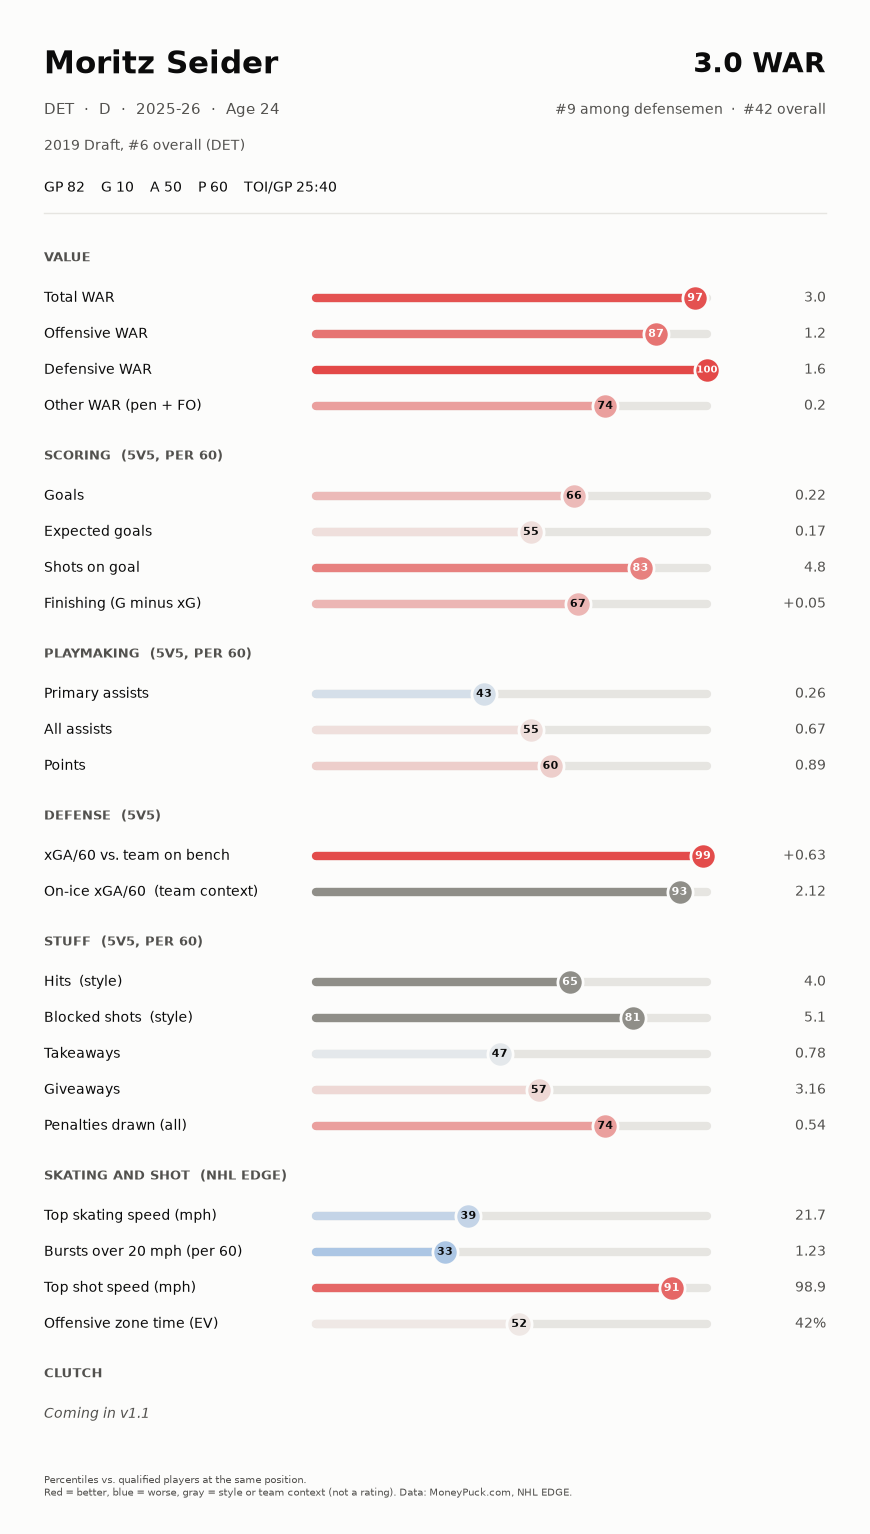

In [ ]:
fig = draw_card(seider, SEASON_LABEL, path=Path("../images/cards") / "seider_2025-26.png")
plt.show()

In [ ]:
cards.to_csv(DATA / f"cards_{SEASON_LABEL}.csv", index=False)
print("Saved the full card table (WAR, stats, EDGE, all percentiles) to", f"data/cards_{SEASON_LABEL}.csv")

Saved the full card table (WAR, stats, EDGE, all percentiles) to data/cards_2025-26.csv


## Next
- Check about 10 cards against hockey knowledge.
- Streamlit app: search a player, see his card. It will read `data/cards_2025-26.csv`, so it never needs to call the NHL.